# Does Education Get You Hired?
### What really decides who gets a job, and for how much, after a Bachelor's degree

**EDA course project, semester B 2025**

| | |
|---|---|
| **Project name** | Correlation between education and career |
| **Group number** | _TODO_ |
| **Presenters** | _TODO_ |
| **Data source** | _TODO: link to the page the data was downloaded from_ |
| **Data in this repo** | [job_placement.csv](https://github.com/aharon429/correlation-between-education-and-career/blob/main/job_placement.csv) |

**Contribution of each team member**
- _TODO_

## The story in one paragraph

We follow 700 graduates of engineering and computing Bachelor's programs at US universities.
For each one we know their field of study, college, GPA, years of work experience, age, gender,
whether they got a job, and their salary. We ask a simple question: **which parts of a
person's education actually matter for their career?** The answer turned out to be less obvious
than we expected. Two things that look important at first (experience and grades) turn out not to
decide who gets hired. *Where* you studied decides that, and grades come back into the picture
only when it comes to salary.

### Research questions
1. **Experience:** Does work experience change the chance of getting hired?
2. **GPA and hiring:** Do students with higher grades get hired more often?
3. **College:** Does the university you went to affect your chance of getting hired?
4. **GPA and salary:** Among those who were hired, do better grades mean a higher salary?
5. **Field of study:** Are some fields (Computer Science, IT, engineering) easier to get hired in or better paid?
6. **Gender:** Is there a gender gap in hiring or in salary?

## 1. Setup and loading the data
The data is read directly from the project's GitHub repository, as the course requires.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

# One consistent, colorblind-safe look for every chart
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993'
INK, INK_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.figsize': (9, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': INK_2,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': '#ecebe7', 'axes.axisbelow': True,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
})
pd.set_option('display.max_columns', 20)

URL = 'https://raw.githubusercontent.com/aharon429/correlation-between-education-and-career/main/job_placement.csv'
raw = pd.read_csv(URL)
print(raw.shape)
raw.head()

(700, 11)


,id,name,gender,age,degree,stream,college_name,placement_status,salary,gpa,years_of_experience
0,1,John Doe,Male,25,Bachelor's,Computer Science,Harvard University,Placed,60000,3.7,2.0
1,2,Jane Smith,Female,24,Bachelor's,Electrical Engineering,Massachusetts Institute of Technology,Placed,65000,3.6,1.0
2,3,Michael Johnson,Male,26,Bachelor's,Mechanical Engineering,Stanford University,Placed,58000,3.8,3.0
3,4,Emily Davis,Female,23,Bachelor's,Information Technology,Yale University,Not Placed,0,3.5,2.0
4,5,David Brown,Male,24,Bachelor's,Computer Science,Princeton University,Placed,62000,3.9,2.0


## 2. First look at the data

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   700 non-null    int64  
 1   name                 700 non-null    str    
 2   gender               700 non-null    str    
 3   age                  700 non-null    int64  
 4   degree               700 non-null    str    
 5   stream               700 non-null    str    
 6   college_name         700 non-null    str    
 7   placement_status     700 non-null    str    
 8   salary               700 non-null    int64  
 9   gpa                  700 non-null    float64
 10  years_of_experience  699 non-null    float64
dtypes: float64(2), int64(3), str(6)
memory usage: 60.3 KB


In [3]:
raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,700.0,NaN,NaN,NaN,350.5,202.21688,1.0,175.75,350.5,525.25,700.0
name,700,66,Emma Martinez,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,700,2,Female,366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,700.0,NaN,NaN,NaN,24.411429,1.164268,23.0,23.0,24.0,26.0,26.0
degree,700,1,Bachelor's,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stream,700,5,Computer Science,214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
college_name,700,44,University of California--Berkeley,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
placement_status,700,2,Placed,570,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary,700.0,NaN,NaN,NaN,52474.285714,25160.331005,0.0,61000.0,64000.0,66000.0,68000.0
gpa,700.0,NaN,NaN,NaN,3.750429,0.121212,3.4,3.7,3.8,3.9,3.9


In [4]:
for col in ['gender', 'degree', 'stream', 'placement_status']:
    print(raw[col].value_counts(), '\n')
print('Number of different colleges:', raw['college_name'].nunique())
print('Number of different names:  ', raw['name'].nunique())

gender
Female    366
Male      334
Name: count, dtype: int64 

degree
Bachelor's    700
Name: count, dtype: int64 

stream
Computer Science                 214
Information Technology           152
Electrical Engineering           112
Mechanical Engineering           111
Electronics and Communication    111
Name: count, dtype: int64 

placement_status
Placed        570
Not Placed    130
Name: count, dtype: int64 

Number of different colleges: 44
Number of different names:   66


**What we notice right away**
- `degree` has a single value (*Bachelor's*) for everyone, so it can't explain anything. We drop it.
- There are only 66 different names for 700 people, which is a hint that rows repeat.
- `salary` is 0 for everyone who was **not placed**. That is not a real salary of zero, it means "no job".
- `years_of_experience` has one missing value.

## 3. Cleaning

In [5]:
# Rows that are identical in every column except the id are the same person entered twice
dup_mask = raw.drop(columns='id').duplicated()
print(f'Duplicate rows: {dup_mask.sum()} of {len(raw)} ({dup_mask.mean():.0%})')
raw[raw.drop(columns='id').duplicated(keep=False)].sort_values(['name', 'college_name']).head(6)

Duplicate rows: 359 of 700 (51%)


,id,name,gender,age,degree,stream,college_name,placement_status,salary,gpa,years_of_experience
443,444,Aiden Davis,Male,24,Bachelor's,Computer Science,University of California--Berkeley,Placed,66000,3.9,3.0
632,633,Aiden Davis,Male,24,Bachelor's,Computer Science,University of California--Berkeley,Placed,66000,3.9,3.0
378,379,Aiden Davis,Male,24,Bachelor's,Computer Science,University of California--Los Angeles,Placed,67000,3.8,3.0
521,522,Aiden Davis,Male,24,Bachelor's,Computer Science,University of California--Los Angeles,Placed,67000,3.8,3.0
599,600,Aiden Davis,Male,24,Bachelor's,Computer Science,University of California--Los Angeles,Placed,67000,3.8,3.0
469,470,Aiden Davis,Male,24,Bachelor's,Computer Science,University of California--San Francisco,Placed,66000,3.8,3.0


About half of the rows are exact copies of another row with a new id. If we kept them, people who
were copied many times would count many times, so we keep one copy of each.

In [6]:
df = (raw.drop(columns='id')
         .drop_duplicates()
         .drop(columns='degree')
         .dropna(subset=['years_of_experience'])
         .copy())

df['placed'] = (df['placement_status'] == 'Placed').astype(int)
df['salary'] = df['salary'].where(df['placed'] == 1)        # 0 means "no job", not a salary
df['years_of_experience'] = df['years_of_experience'].astype(int)

placed = df[df['placed'] == 1]
print(f'Clean data: {len(df)} graduates, {len(placed)} placed ({df.placed.mean():.0%})')
df.head()

Clean data: 340 graduates, 278 placed (82%)


,name,gender,age,stream,college_name,placement_status,salary,gpa,years_of_experience,placed
0,John Doe,Male,25,Computer Science,Harvard University,Placed,60000.0,3.7,2,1
1,Jane Smith,Female,24,Electrical Engineering,Massachusetts Institute of Technology,Placed,65000.0,3.6,1,1
2,Michael Johnson,Male,26,Mechanical Engineering,Stanford University,Placed,58000.0,3.8,3,1
3,Emily Davis,Female,23,Information Technology,Yale University,Not Placed,NaN,3.5,2,0
4,David Brown,Male,24,Computer Science,Princeton University,Placed,62000.0,3.9,2,1


## 4. Question 1: Does work experience change the chance of getting hired?

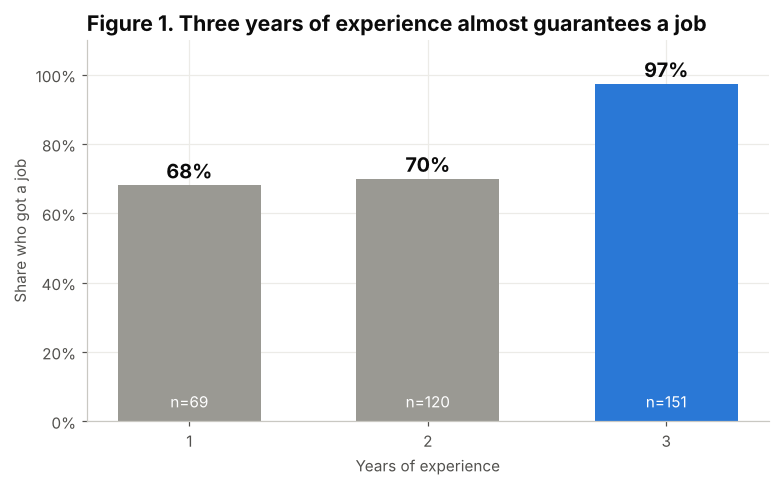

Chi-square test: chi2=44.4, p=2.3e-10


In [7]:
by_exp = df.groupby('years_of_experience')['placed'].agg(rate='mean', n='size')

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [GRAY, GRAY, BLUE]
bars = ax.bar(by_exp.index.astype(str), by_exp['rate'], color=colors, width=0.6)
for b, (rate, n) in zip(bars, by_exp.values):
    ax.text(b.get_x() + b.get_width() / 2, rate + 0.02, f'{rate:.0%}', ha='center', fontsize=13, fontweight='bold')
    ax.text(b.get_x() + b.get_width() / 2, 0.04, f'n={int(n)}', ha='center', color='white', fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 1.1)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel('Years of experience')
ax.set_ylabel('Share who got a job')
ax.set_title('Figure 1. Three years of experience almost guarantees a job')
plt.show()

table = pd.crosstab(df['years_of_experience'], df['placed'])
chi2, p, *_ = stats.chi2_contingency(table)
print(f'Chi-square test: chi2={chi2:.1f}, p={p:.1e}')

**Answer (for now):** Yes, strongly. With 1 or 2 years of experience about 7 in 10 graduates got a job.
With 3 years, **97%** did. The jump happens between 2 and 3 years, not gradually.
Keep this chart in mind, we will come back to it in Question 3.

## 5. Question 2: Do students with higher grades get hired more often?

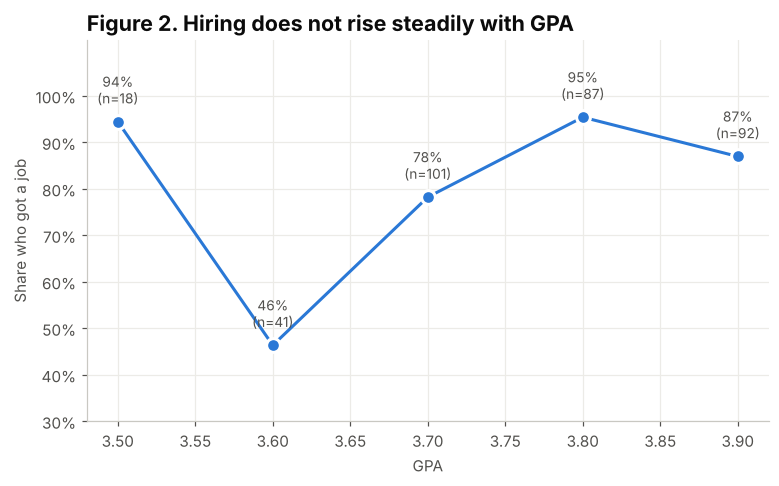

In [8]:
by_gpa = df.groupby('gpa')['placed'].agg(rate='mean', n='size')
by_gpa = by_gpa[by_gpa['n'] >= 5]          # GPA 3.4 has a single student

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_gpa.index, by_gpa['rate'], color=BLUE, lw=2, marker='o', ms=9,
        markeredgecolor='white', markeredgewidth=2)
for g, (rate, n) in by_gpa.iterrows():
    ax.annotate(f'{rate:.0%}\n(n={int(n)})', (g, rate), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=9, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0.3, 1.12)
ax.set_yticks(np.arange(0.3, 1.01, 0.1))
ax.set_xlabel('GPA')
ax.set_ylabel('Share who got a job')
ax.set_title('Figure 2. Hiring does not rise steadily with GPA')
plt.show()

The line zig-zags. A GPA of 3.5 is hired almost as often as 3.8, while 3.6 is hired less than half
the time. That is strange if grades were the reason. Maybe GPA is just travelling together with
something else, for example experience.

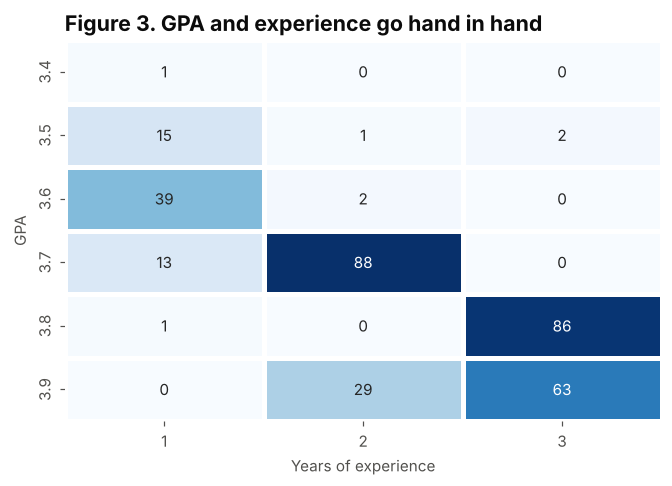

Correlation between GPA and experience: 0.76


In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ct = pd.crosstab(df['gpa'], df['years_of_experience'])
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=2, linecolor='white', ax=ax)
ax.set_xlabel('Years of experience')
ax.set_ylabel('GPA')
ax.set_title('Figure 3. GPA and experience go hand in hand')
plt.show()
print('Correlation between GPA and experience:', round(df['gpa'].corr(df['years_of_experience']), 2))

GPA and experience are tightly linked (correlation 0.76). Students with 3.8 to 3.9 almost all have
3 years of experience, and those with 3.5 to 3.6 almost all have 1 year. So to know which one
really matters we put both into one model (logistic regression) and let them compete.

In [10]:
logit = smf.logit('placed ~ gpa + years_of_experience', data=df).fit(disp=0)
summary = pd.DataFrame({'coef': logit.params, 'p-value': logit.pvalues}).round(3)
summary

,coef,p-value
Intercept,5.968,0.353
gpa,-1.937,0.293
years_of_experience,1.359,0.000


**Answer:** Once we know how much experience someone has, GPA adds nothing to their chance of
being hired (p-value well above 0.05, and the sign even turns negative). Experience stays strongly
significant. **Grades look important for hiring only because good students also tend to have more experience.**
But is experience itself the real reason? Question 3 will surprise us.

## 6. Question 3: Does the university you went to matter?

25 colleges have a single graduate in the data, too few to judge.


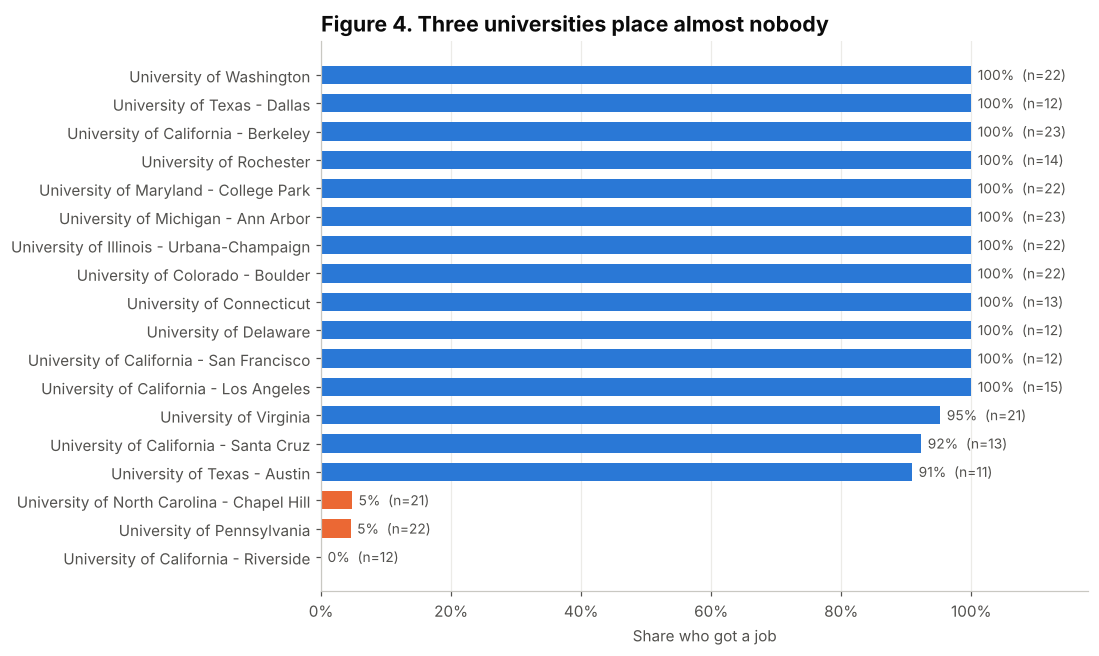

Chi-square test, college vs placement: p = 7.6e-42


In [11]:
col = df.groupby('college_name').agg(n=('placed', 'size'), rate=('placed', 'mean'),
                                     gpa=('gpa', 'mean'), exp=('years_of_experience', 'mean'))
print(f"{(col['n'] == 1).sum()} colleges have a single graduate in the data, too few to judge.")
big = col[col['n'] >= 10].sort_values('rate')

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = [ORANGE if r < 0.5 else BLUE for r in big['rate']]
ax.barh(big.index.str.replace('--', ' - '), big['rate'], color=colors, height=0.65)
for i, (rate, n) in enumerate(zip(big['rate'], big['n'])):
    ax.text(rate + 0.01, i, f'{rate:.0%}  (n={n})', va='center', fontsize=9, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 1.18)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel('Share who got a job')
ax.set_title('Figure 4. Three universities place almost nobody')
ax.grid(axis='y', visible=False)
plt.show()

chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df['college_name'], df['placed']))
print(f'Chi-square test, college vs placement: p = {p:.1e}')

Is this just because those three schools have weaker students? Let's compare their students with everyone else.

In [12]:
low = big[big['rate'] < 0.5].index
df['college_group'] = np.where(df['college_name'].isin(low), 'Low-placement colleges', 'All other colleges')
compare = (df.groupby('college_group')
             .agg(graduates=('placed', 'size'), placement_rate=('placed', 'mean'),
                  mean_gpa=('gpa', 'mean'), mean_experience=('years_of_experience', 'mean')))
display(compare.round(2))
display(big.loc[low].round(2))

,graduates,placement_rate,mean_gpa,mean_experience
college_group,,,,
All other colleges,285,0.97,3.77,2.36
Low-placement colleges,55,0.04,3.71,1.64


,n,rate,gpa,exp
college_name,,,,
University of California--Riverside,12,0.00,3.9,2.00
University of Pennsylvania,22,0.05,3.7,2.00
University of North Carolina--Chapel Hill,21,0.05,3.6,1.05


**Answer:** The university is the strongest factor in the data. Most universities with 10+
graduates placed (almost) **everyone**, but the University of Pennsylvania placed 1 of 22,
UNC Chapel Hill 1 of 21 and UC Riverside 0 of 12. Their students' grades are not weaker:
UC Riverside's graduates average a GPA of **3.9**, among the highest in the data, and an Ivy League
school (Penn) is at the bottom, so prestige doesn't explain it either.

But look at the last column: students at the low-placement colleges also have **less experience**
(1.6 years vs 2.4), and **none of them has 3 years**. That makes us suspicious of Question 1.

### The twist: was it ever about experience?
Let's repeat Figure 1, but separately for the three low-placement colleges and for everyone else.

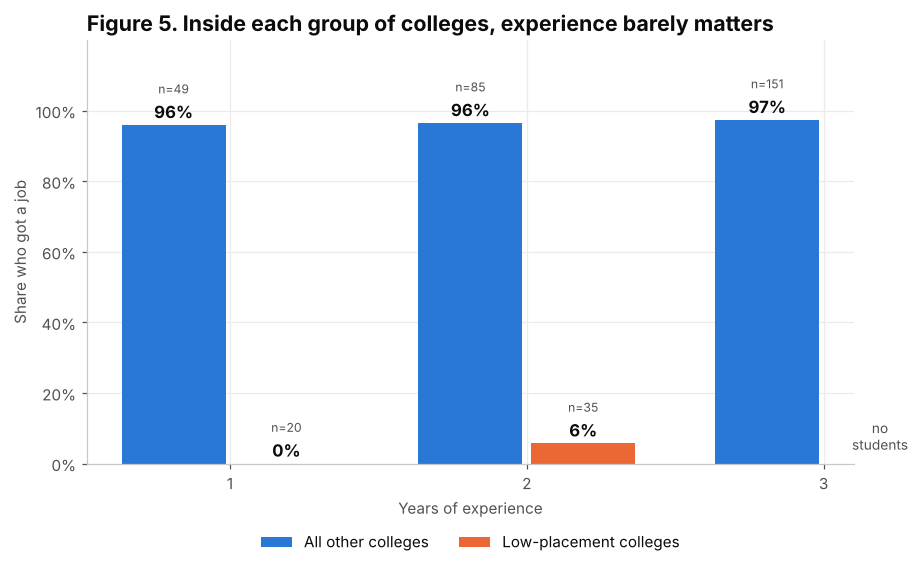

Outside the 3 colleges, experience vs placement: chi-square p = 0.86


In [13]:
twist = (df.groupby(['college_group', 'years_of_experience'])['placed']
           .agg(rate='mean', n='size').reset_index())

fig, ax = plt.subplots(figsize=(9, 5))
width = 0.38
for i, (grp, color) in enumerate([('All other colleges', BLUE), ('Low-placement colleges', ORANGE)]):
    d = twist[twist['college_group'] == grp]
    x = d['years_of_experience'] + (i - 0.5) * width
    ax.bar(x, d['rate'], width=width - 0.03, color=color, label=grp)
    for xi, r, n in zip(x, d['rate'], d['n']):
        ax.text(xi, r + 0.02, f'{r:.0%}', ha='center', fontsize=11, fontweight='bold')
        ax.text(xi, max(r, 0) + 0.09, f'n={n}', ha='center', fontsize=8, color=INK_2)
ax.text(3 + 0.5 * width, 0.03, 'no\nstudents', ha='center', fontsize=9, color=INK_2, va='bottom')
ax.set_xticks([1, 2, 3])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 1.2)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel('Years of experience')
ax.set_ylabel('Share who got a job')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2)
ax.set_title('Figure 5. Inside each group of colleges, experience barely matters')
plt.show()

other = df[df['college_group'] == 'All other colleges']
_, p_other, *_ = stats.chi2_contingency(pd.crosstab(other['years_of_experience'], other['placed']))
print(f'Outside the 3 colleges, experience vs placement: chi-square p = {p_other:.2f}')

**This changes the story.** Outside the three low-placement colleges, graduates with 1, 2 or 3 years
of experience are hired at the same rate (96% to 97%, no significant difference). The big gap in
Figure 1 appeared only because the colleges that hardly place anyone also happen to have no
students with 3 years of experience. This is a classic example of a **confounding variable**:
college drives both experience and hiring, so experience *looked* like the cause.

And since GPA only looked important because of experience (Question 2), the whole chain
"good grades → more experience → job" falls apart. In this data, **getting hired is about where you studied.**

## 7. Question 4: Among those hired, do better grades mean a higher salary?

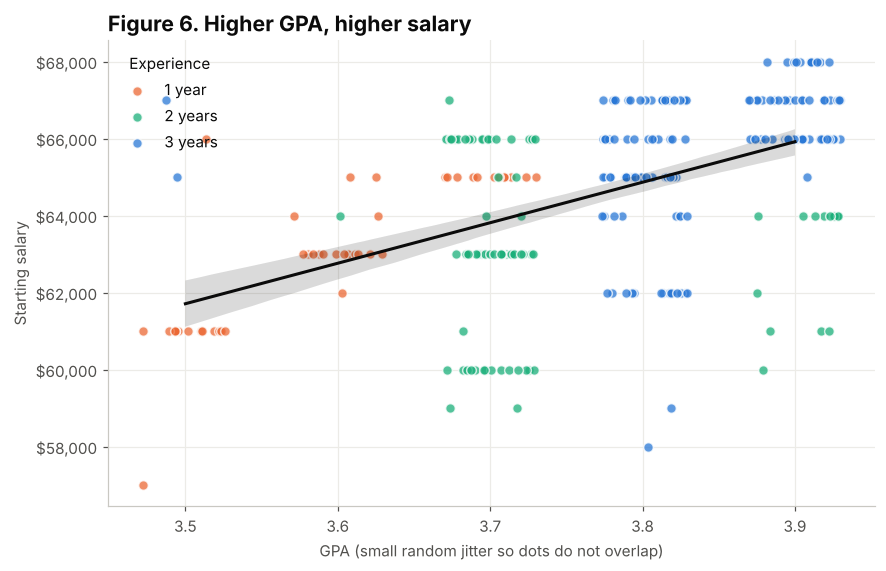

Pearson r = 0.52, p = 1.9e-20


In [14]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 5.5))
for exp, color in zip([1, 2, 3], [ORANGE, AQUA, BLUE]):
    d = placed[placed['years_of_experience'] == exp]
    ax.scatter(d['gpa'] + rng.uniform(-0.03, 0.03, len(d)), d['salary'], s=40, alpha=0.75,
               color=color, edgecolor='white', linewidth=1, label=f'{exp} year{"s" if exp > 1 else ""}')
sns.regplot(data=placed, x='gpa', y='salary', scatter=False, ax=ax, color=INK, line_kws={'lw': 2})
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
ax.set_xlabel('GPA (small random jitter so dots do not overlap)')
ax.set_ylabel('Starting salary')
ax.legend(title='Experience', frameon=False, loc='upper left')
ax.set_title('Figure 6. Higher GPA, higher salary')
plt.show()

r, p = stats.pearsonr(placed['gpa'], placed['salary'])
print(f'Pearson r = {r:.2f}, p = {p:.1e}')

After the twist in Question 3 we don't trust a simple correlation anymore. So we test GPA two ways:
together with experience, and then also comparing only graduates **of the same college**.

In [15]:
m1 = smf.ols('salary ~ gpa + years_of_experience', data=placed).fit()
m2 = smf.ols('salary ~ gpa + years_of_experience + C(college_name)', data=placed).fit()
m0 = smf.ols('salary ~ C(college_name)', data=placed).fit()
results = pd.DataFrame({
    'GPA + experience':           [m1.params['gpa'], m1.pvalues['gpa'], m1.rsquared],
    'GPA + experience + college': [m2.params['gpa'], m2.pvalues['gpa'], m2.rsquared],
}, index=['$ per 1 GPA point', 'GPA p-value', 'R squared']).T
display(results.style.format({'$ per 1 GPA point': '{:,.0f}', 'GPA p-value': '{:.1e}', 'R squared': '{:.2f}'}))
print(f'College alone explains {m0.rsquared:.0%} of the differences in salary.')

,$ per 1 GPA point,GPA p-value,R squared
GPA + experience,"6,205",1.2e-04,0.30
GPA + experience + college,"4,796",7.3e-05,0.94


College alone explains 89% of the differences in salary.


**Answer:** Yes, and this one survives every check. Among graduates of the **same college with the
same experience**, each extra 0.1 GPA point is still worth about **$480 more** per year (p < 0.001).
College again is the biggest factor (it explains most of the differences in salary on its own), but
grades add a real, measurable bonus on top. So **the college decides whether you get hired, and your
grades help decide how much you're paid.**

## 8. Question 5: Are some fields of study easier to get hired in or better paid?

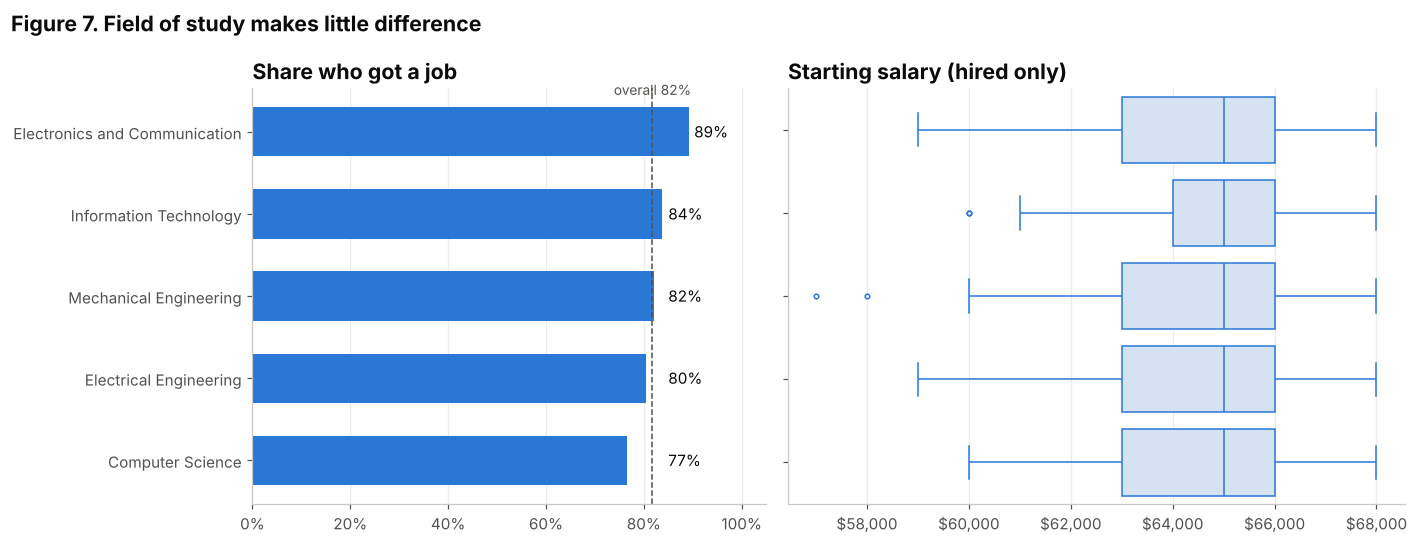

Placement by field, chi-square p = 0.38
Salary by field, ANOVA p = 0.58


In [16]:
order = df.groupby('stream')['placed'].mean().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.2]})

rates = df.groupby('stream')['placed'].mean().loc[order]
axes[0].barh(order, rates, color=BLUE, height=0.6)
axes[0].axvline(df['placed'].mean(), color=INK_2, ls='--', lw=1)
axes[0].text(df['placed'].mean(), 4.45, f"overall {df['placed'].mean():.0%}", color=INK_2, fontsize=9, ha='center')
for i, r in enumerate(rates):
    axes[0].text(max(r, 0.84) + 0.01, i, f'{r:.0%}', va='center', fontsize=10)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_xlim(0, 1.05)
axes[0].set_title('Share who got a job')
axes[0].grid(axis='y', visible=False)

sns.boxplot(data=placed, y='stream', x='salary', order=order, color='#cfe1f7', ax=axes[1],
            linecolor=BLUE, fliersize=3)
axes[1].set_yticklabels([])
axes[1].set_ylabel('')
axes[1].set_xlabel('')
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
axes[1].set_title('Starting salary (hired only)')
fig.suptitle('Figure 7. Field of study makes little difference', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

_, p_place, *_ = stats.chi2_contingency(pd.crosstab(df['stream'], df['placed']))
_, p_sal = stats.f_oneway(*[g['salary'] for _, g in placed.groupby('stream')])
print(f'Placement by field, chi-square p = {p_place:.2f}')
print(f'Salary by field, ANOVA p = {p_sal:.2f}')

**Answer:** No clear difference. Computer Science, the most popular field, actually has the lowest
placement rate (77%) and Electronics and Communication the highest (89%), but the gap is not
statistically significant, and salaries are almost the same in every field. In this data, *what*
you studied matters much less than *where* and *how much experience* you have.

## 9. Question 6: Is there a gender gap?

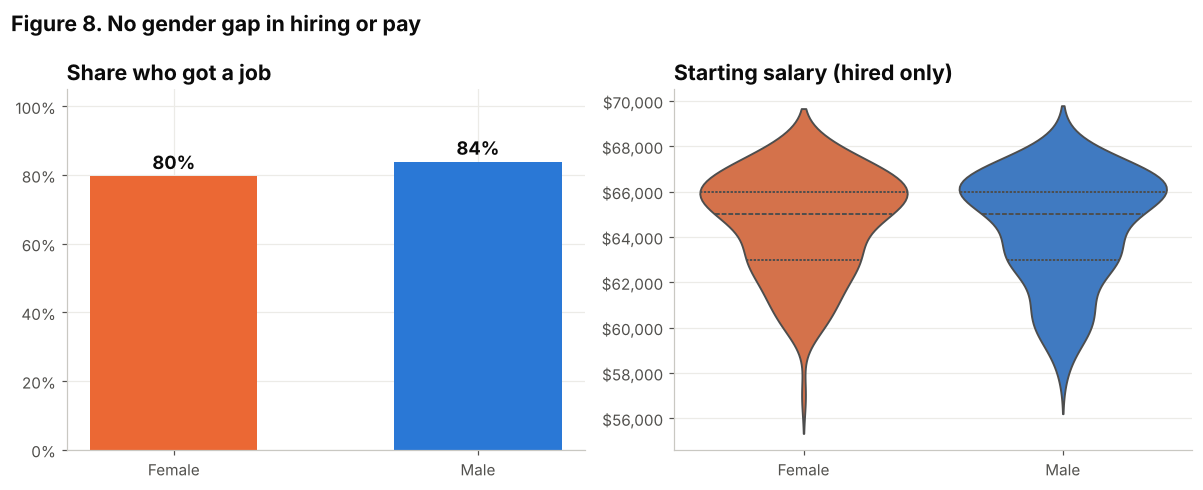

Placement by gender, chi-square p = 0.39
Salary by gender, t-test p = 0.52


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
g = df.groupby('gender')['placed'].mean()
axes[0].bar(g.index, g.values, color=[ORANGE, BLUE], width=0.55)
for i, v in enumerate(g.values):
    axes[0].text(i, v + 0.02, f'{v:.0%}', ha='center', fontsize=12, fontweight='bold')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Share who got a job')

sns.violinplot(data=placed, x='gender', y='salary', hue='gender', order=['Female', 'Male'],
               hue_order=['Female', 'Male'], palette=[ORANGE, BLUE],
               inner='quartile', legend=False, ax=axes[1])
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
axes[1].set_xlabel('')
axes[1].set_ylabel('')
axes[1].set_title('Starting salary (hired only)')
fig.suptitle('Figure 8. No gender gap in hiring or pay', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

_, p_place, *_ = stats.chi2_contingency(pd.crosstab(df['gender'], df['placed']))
t, p_sal = stats.ttest_ind(*[grp['salary'] for _, grp in placed.groupby('gender')])
print(f'Placement by gender, chi-square p = {p_place:.2f}')
print(f'Salary by gender, t-test p = {p_sal:.2f}')

**Answer:** No. Men and women are hired at similar rates and earn almost exactly the same
starting salary. Neither difference is statistically significant.

## 10. Three key insights

**1. Where you studied decides whether you get hired.** At most universities 97% of graduates found
a job, while three universities (Penn, UNC Chapel Hill, UC Riverside) placed only 4%, even though
their students' grades are just as good. Prestige doesn't explain it: an Ivy League school is at the bottom.

**2. Experience and grades only *look* like they matter for hiring.** Overall, 3 years of experience
seems to lift the hiring rate from 70% to 97%. But inside each group of colleges, experience makes no
difference. The low-placement colleges simply have no students with 3 years of experience. GPA, in turn,
looks important only because it moves together with experience. A clear lesson about confounding variables.

**3. Grades do pay off, in salary.** Among those hired, a higher GPA means a higher starting salary,
about $480 more per 0.1 GPA point, even when comparing graduates of the same college with the same
experience. Field of study and gender showed no meaningful difference in hiring or pay.

### What didn't work, and limitations
- Field of study and gender gave no significant results. That is a finding too, but a quiet one.
- About half the original rows were duplicates, so after cleaning we have 340 graduates. Several
  colleges appear only once, so we judged colleges only when they had 10 or more graduates.
- Everyone has a Bachelor's degree, GPA only ranges from 3.4 to 3.9 and experience from 1 to 3 years,
  so we can't say anything about lower grades, other degrees or longer careers.
- The data looks partly generated (a few names repeated many times, round salaries), so the
  conclusions describe this dataset and may not hold for real graduates.